# Session 7 — Benchmarking, Ablation Studies & Reporting Standards
### Hands-on Lab · Research Methods & Scientific Integrity in AI
**UNMSM Doctoral Program in Deep Technologies · Dr. Loveleen Gaur**

---

**What you will do tonight (no GPU required — everything runs on the free CPU tier in a few minutes):**

| # | Exercise | The rigor it builds |
|---|----------|---------------------|
| 1 | Weak vs. tuned baseline | A "win" against an *untuned* baseline is not a win |
| 2 | Seeds & variance | One lucky seed is not a result — report mean ± std |
| 3 | Ablation study | Attribute the gain to a specific component |
| 4 | Generate a Model Card | Mitchell et al. (2019) — 9 sections |
| 5 | Generate a Datasheet | Gebru et al. (2021) — 7 sections |
| 6 | Documentation scorecard | Self-audit completeness & reproducibility |

**Part B — extension (depth + portfolio):**

| # | Exercise | The rigor it builds |
|---|----------|---------------------|
| 7 | Significance & confidence intervals | Test a difference before you claim it |
| 8 | Compute-matched comparison | A bigger budget is a different experiment |
| 9 | The data-leakage trap | Leakage can manufacture accuracy from noise |
| 10 | Ablation error bars + multiple comparisons | Visualise attribution; correct for many tests |
| 11 | EU AI Act · Annex IV crosswalk | Turn the Model Card into a compliance gap table |
| 12 | Reproducibility report bundle | Zip a submission a stranger could re-run |

**How to use this notebook:** run the cells top to bottom (`Shift+Enter`). Cells marked **🛠 YOUR TURN** are where you edit. Cells marked **🧪** produce a result to discuss.

> Every empirical claim in tonight's slides is sourced. Full reference list is on the last slide.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

# Sesión 7 — Benchmarking, estudios de ablación y estándares de reporte
### Laboratorio práctico · Métodos de Investigación e Integridad Científica en IA
**Programa Doctoral en Tecnologías Profundas, UNMSM · Dra. Loveleen Gaur**

**Qué harás hoy (no se necesita GPU; todo corre en la capa CPU gratuita en pocos minutos):**

| # | Ejercicio | El rigor que construye |
|---|-----------|------------------------|
| 1 | Línea base débil vs. ajustada | Una "victoria" contra una línea base *sin ajustar* no es una victoria |
| 2 | Semillas y varianza | Una semilla afortunada no es un resultado: reporta media ± desv. est. |
| 3 | Estudio de ablación | Atribuye la mejora a un componente específico |
| 4 | Generar una Model Card | Mitchell et al. (2019): 9 secciones |
| 5 | Generar una Datasheet | Gebru et al. (2021): 7 secciones |
| 6 | Scorecard de documentación | Autoauditoría de completitud y reproducibilidad |

**Parte B — extensión (profundidad + portafolio):**

| # | Ejercicio | El rigor que construye |
|---|-----------|------------------------|
| 7 | Significancia e intervalos de confianza | Prueba una diferencia antes de afirmarla |
| 8 | Comparación con cómputo igualado | Un presupuesto mayor es otro experimento |
| 9 | La trampa de la fuga de datos | La fuga puede fabricar precisión a partir de ruido |
| 10 | Barras de error en la ablación + comparaciones múltiples | Visualiza la atribución; corrige por muchas pruebas |
| 11 | Ley de IA de la UE · cruce con el Anexo IV | Convierte la Model Card en una tabla de brechas de cumplimiento |
| 12 | Paquete de reporte de reproducibilidad | Comprime una entrega que un desconocido podría volver a correr |

**Cómo usar este cuaderno:** ejecuta las celdas de arriba hacia abajo (`Shift+Enter`). Las celdas marcadas **🛠 TU TURNO** son las que editas. Las marcadas **🧪** producen un resultado para discutir.

> Cada afirmación empírica de las diapositivas de hoy tiene fuente. La lista completa está en la última diapositiva.

</details>

**Student / Estudiante:** Angela Milén Acosta Ticona · COD. 26207270 · Doctorado en Tecnologías Profundas, UNMSM
**Deliverable N° 7 · Session 7 — Model Card + Datasheet for my own research**

| Part of this notebook | Data it uses |
|---|---|
| Lab exercises 1–3 and 7–10 (benchmarking, seeds, ablation, significance, compute, leakage) | The class dataset (Wisconsin Breast Cancer), unchanged, plus a ✍️ **Your turn** cell where the lab asks for one |
| **Exercise 4 · Model Card** and **Exercise 5 · Datasheet** | **My thesis:** the planned XGBoost classifier and my SUNAT/Veritrade paper-import data (HS Chapter 48, 2022–2026) |
| Exercises 6, 11, 12 (scorecard, Annex IV crosswalk, bundle) | Run on **my** Model Card and Datasheet |

**Why the Model Card is prospective.** My customs data are downloaded but still being cleaned, so no thesis model has been trained yet. The card documents the planned model, the evaluation protocol fixed in advance, and every gap as `"UNKNOWN — to investigate"`. It contains **no invented results**: the class's rule is that *the gaps are the point*.

> **ES:** Los ejercicios de laboratorio usan el dataset de la clase. La Model Card y la Datasheet describen **mi tesis**. La Model Card es **prospectiva**: mis datos aduaneros aún se están limpiando, así que documenta el modelo planeado y marca los vacíos como "UNKNOWN — to investigate", sin inventar resultados.


## 0 · Setup
Run once. Installs nothing extra — all of this ships with Colab.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## 0 · Configuración
Ejecuta una sola vez. No instala nada extra: todo viene incluido en Colab.

</details>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# A real, small, fast tabular benchmark: Wisconsin Breast Cancer (569 samples, 30 features).
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = list(data.feature_names)
print(f"Dataset: {data.DESCR.splitlines()[0]}")
print(f"Samples: {X.shape[0]} | Features: {X.shape[1]} | Classes: {np.bincount(y)} (0=malignant, 1=benign)")

# Honest split: train / test, stratified so class balance is preserved (Session 6 idea).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]}  Test: {X_test.shape[0]}")

Dataset: .. _breast_cancer_dataset:
Samples: 569 | Features: 30 | Classes: [212 357] (0=malignant, 1=benign)
Train: 426  Test: 143


## Exercise 1 · The weak-baseline illusion
**The hook, in code.** Dacrema et al. (2019) found that 6 of 7 reproducible neural recommenders were beaten by *simple, well-tuned* heuristics. The villain was rarely the fancy model — it was the **lazy baseline**.

Here we play both roles:
- a **"fancy" model** (gradient boosting) that we tune a little, and
- a **logistic-regression baseline** that we first leave *untuned*, then tune *as hard as the fancy model*.

Watch the "improvement" shrink — or vanish — once the baseline gets a fair shake.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 1 · La ilusión de la línea base débil
**El gancho, en código.** Dacrema et al. (2019) hallaron que 6 de 7 recomendadores neuronales reproducibles eran superados por heurísticas *simples y bien ajustadas*. El villano rara vez era el modelo sofisticado: era la **línea base perezosa**.

Aquí jugamos ambos papeles:
- un **modelo "sofisticado"** (gradient boosting) que ajustamos un poco, y
- una **línea base de regresión logística** que primero dejamos *sin ajustar* y luego ajustamos *con el mismo esfuerzo* que el modelo sofisticado.

Observa cómo la "mejora" se encoge, o desaparece, cuando la línea base recibe un trato justo.

</details>

In [2]:
# --- The "fancy" model, lightly tuned ---
fancy = make_pipeline(StandardScaler(),
                      GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                 max_depth=3, random_state=RANDOM_STATE))
fancy.fit(X_train, y_train)
acc_fancy = accuracy_score(y_test, fancy.predict(X_test))

# --- Baseline #1: untuned logistic regression (the straw man) ---
weak = make_pipeline(StandardScaler(),
                     LogisticRegression(C=0.001, max_iter=2000, random_state=RANDOM_STATE))
weak.fit(X_train, y_train)
acc_weak = accuracy_score(y_test, weak.predict(X_test))

print(f"Fancy model (gradient boosting)        : {acc_fancy:.4f}")
print(f"UNTUNED baseline (logistic, C=0.001)   : {acc_weak:.4f}")
print(f"Apparent improvement over weak baseline: {acc_fancy - acc_weak:+.4f}  <-- looks impressive!")

Fancy model (gradient boosting)        : 0.9580
UNTUNED baseline (logistic, C=0.001)   : 0.9161
Apparent improvement over weak baseline: +0.0420  <-- looks impressive!


In [3]:
# --- Baseline #2: now tune the baseline AS HARD as we'd tune our own model ---
param_grid = {"logisticregression__C": np.logspace(-3, 2, 12)}
strong = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    param_grid, cv=5, scoring="accuracy", n_jobs=-1)
strong.fit(X_train, y_train)
acc_strong = accuracy_score(y_test, strong.predict(X_test))

print(f"Fancy model                            : {acc_fancy:.4f}")
print(f"TUNED baseline (best C={strong.best_params_['logisticregression__C']:.4g}) : {acc_strong:.4f}")
print(f"HONEST improvement over tuned baseline : {acc_fancy - acc_strong:+.4f}")
print()
print("Discuss: how much of the original 'improvement' survived a fair comparison?")

Fancy model                            : 0.9580
TUNED baseline (best C=0.06579) : 0.9790
HONEST improvement over tuned baseline : -0.0210

Discuss: how much of the original 'improvement' survived a fair comparison?


**🧪 Discuss.** The first comparison flattered the fancy model because the baseline was crippled (`C=0.001` heavily under-regularised it). The fairness test from the slides: *if a reviewer tuned your baseline with the same care you gave your model, would your gain survive?*

> The lesson is **not** "boosting is bad." It is: a comparison is only a comparison when both sides got equal effort, equal data, equal compute.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Discute.** La primera comparación favoreció al modelo sofisticado porque la línea base estaba lisiada (`C=0.001` la regularizaba en exceso). La prueba de justicia de las diapositivas: *si un revisor ajustara tu línea base con el mismo cuidado que diste a tu modelo, ¿sobreviviría tu mejora?*

> La lección **no** es "el boosting es malo". Es: una comparación solo es una comparación cuando ambos lados recibieron el mismo esfuerzo, los mismos datos y el mismo cómputo.

</details>

## Exercise 2 · One seed is not a result
A single training run reports a single number. But stochastic training (initialisation, data order, sampling) means that number is **a draw from a distribution**. Reporting one draw is how a paper claims "89.7% beats 89.2%" when the real difference is noise (the Session 6 story).

We run the fancy model over **10 seeds** and look at the spread.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 2 · Una semilla no es un resultado
Una sola corrida de entrenamiento reporta un solo número. Pero el entrenamiento estocástico (inicialización, orden de los datos, muestreo) hace que ese número sea **una extracción de una distribución**. Reportar una sola extracción es como un artículo afirma que "89.7% supera a 89.2%" cuando la diferencia real es ruido (la historia de la Sesión 6).

Corremos el modelo sofisticado con **10 semillas** y miramos la dispersión.

</details>

In [4]:
seeds = range(10)
accs = []
for s in seeds:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    m = make_pipeline(StandardScaler(),
                      GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                 max_depth=3, random_state=s))
    m.fit(Xtr, ytr)
    accs.append(accuracy_score(yte, m.predict(Xte)))

accs = np.array(accs)
print("Per-seed accuracies:", np.round(accs, 4))
print(f"\nMean ± std : {accs.mean():.4f} ± {accs.std():.4f}")
print(f"Min / Max  : {accs.min():.4f} / {accs.max():.4f}   (spread = {accs.max()-accs.min():.4f})")
print(f"\nIf you reported only the BEST seed you'd claim {accs.max():.4f}.")
print(f"If you reported only the WORST seed you'd claim {accs.min():.4f}.")
print("Same model, same data, same code. The only thing that changed was the seed.")

Per-seed accuracies: [0.951 0.958 0.972 0.958 0.979 0.972 0.979 0.965 0.972 0.972]

Mean ± std : 0.9678 ± 0.0090
Min / Max  : 0.9510 / 0.9790   (spread = 0.0280)

If you reported only the BEST seed you'd claim 0.9790.
If you reported only the WORST seed you'd claim 0.9510.
Same model, same data, same code. The only thing that changed was the seed.


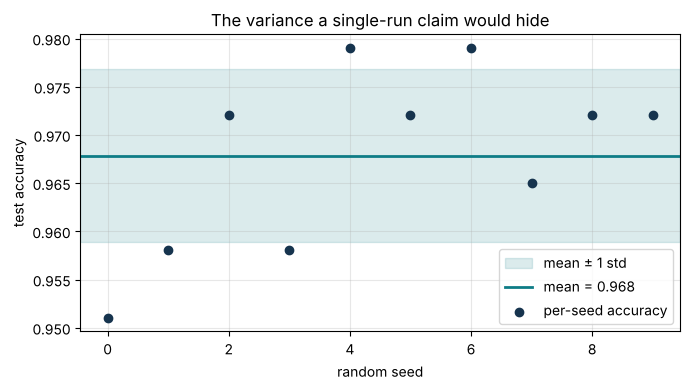

In [5]:
plt.figure()
plt.axhspan(accs.mean()-accs.std(), accs.mean()+accs.std(), color="#0E7C86", alpha=0.15, label="mean ± 1 std")
plt.axhline(accs.mean(), color="#0E7C86", lw=2, label=f"mean = {accs.mean():.3f}")
plt.scatter(list(seeds), accs, color="#16344E", zorder=5, label="per-seed accuracy")
plt.xlabel("random seed"); plt.ylabel("test accuracy")
plt.title("The variance a single-run claim would hide")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

**🧪 Discuss.** Best practice (NeurIPS / ICML reproducibility checklists): report **mean ± std over ≥5 seeds**, and ideally a statistical test before claiming one method beats another. A "+0.3%" gain inside a ±0.8% band is not a finding.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Discute.** La buena práctica (listas de verificación de reproducibilidad de NeurIPS / ICML): reporta **media ± desv. est. sobre ≥5 semillas** e, idealmente, una prueba estadística antes de afirmar que un método supera a otro. Una "mejora" de +0.3% dentro de una banda de ±0.8% no es un hallazgo.

</details>

## Exercise 3 · A proper ablation study
An ablation removes **one component at a time** to attribute the gain. Here the "components" are groups of input features, plus the scaling step. We turn each off, keep everything else fixed, and measure the drop — reporting **mean ± std over seeds**, never a single run.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 3 · Un estudio de ablación como corresponde
Una ablación quita **un componente a la vez** para atribuir la mejora. Aquí los "componentes" son grupos de variables de entrada, más el paso de escalado. Apagamos cada uno, mantenemos todo lo demás fijo y medimos la caída, reportando **media ± desv. est. sobre semillas**, nunca una sola corrida.

</details>

In [6]:
# Group the 30 features into the 3 blocks the dataset is built from.
def feature_block(prefix):
    return [i for i, n in enumerate(feature_names) if n.startswith(prefix)]
blocks = {
    "mean features":    feature_block("mean"),
    "error features":   feature_block("radius error") + [i for i,n in enumerate(feature_names) if "error" in n],
    "worst features":   feature_block("worst"),
}
# de-duplicate the 'error' block
blocks["error features"] = sorted(set(blocks["error features"]))

def evaluate(use_idx, scale=True, seeds=range(5)):
    scores = []
    for s in seeds:
        Xtr, Xte, ytr, yte = train_test_split(X[:, use_idx], y, test_size=0.25,
                                              stratify=y, random_state=s)
        steps = [StandardScaler()] if scale else []
        steps.append(GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=s))
        m = make_pipeline(*steps); m.fit(Xtr, ytr)
        scores.append(accuracy_score(yte, m.predict(Xte)))
    return np.mean(scores), np.std(scores)

all_idx = list(range(X.shape[1]))
rows = []
full_mean, full_std = evaluate(all_idx)
rows.append(("FULL model (all features + scaling)", full_mean, full_std, 0.0))

for name, idx in blocks.items():
    keep = [i for i in all_idx if i not in idx]
    m_, s_ = evaluate(keep)
    rows.append((f"– remove {name}", m_, s_, m_ - full_mean))

m_, s_ = evaluate(all_idx, scale=False)
rows.append(("– remove feature scaling", m_, s_, m_ - full_mean))

abl = pd.DataFrame(rows, columns=["Configuration", "Accuracy (mean)", "Std", "Δ vs full"])
abl[["Accuracy (mean)", "Std", "Δ vs full"]] = abl[["Accuracy (mean)", "Std", "Δ vs full"]].round(4)
abl

,Configuration,Accuracy (mean),Std,Δ vs full
0,FULL model (all features + scaling),0.9636,0.0103,0.0000
1,– remove mean features,0.9552,0.0144,-0.0084
2,– remove error features,0.9594,0.0128,-0.0042
3,– remove worst features,0.9385,0.0136,-0.0252
4,– remove feature scaling,0.9636,0.0103,0.0000


**🧪 Read the table.** The components with the **most negative Δ** are doing the most work; a near-zero Δ means a component barely earns its place — and saying so is an honest **negative result**, exactly the kind the literature under-reports.

**🛠 YOUR TURN.** Change `seeds=range(5)` to `range(10)` in `evaluate`, or regroup the feature blocks, and see whether your conclusions are stable. Stability across seeds is what makes an ablation trustworthy.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Lee la tabla.** Los componentes con el **Δ más negativo** son los que más trabajan; un Δ cercano a cero significa que un componente apenas se justifica, y decirlo es un **resultado negativo** honesto, exactamente el tipo que la literatura subreporta.

**🛠 TU TURNO.** Cambia `seeds=range(5)` por `range(10)` en `evaluate`, o reagrupa los bloques de variables, y verifica si tus conclusiones se mantienen. La estabilidad entre semillas es lo que hace confiable una ablación.

</details>

### ✍️ Your turn · Exercise 3 — 10 seeds instead of 5
**Question:** are the ablation conclusions stable when the number of seeds doubles?
> **ES:** ¿Las conclusiones de la ablación se mantienen al duplicar las semillas?


In [7]:
# Your turn, Exercise 3: same ablation with 10 seeds instead of 5
configs = [("FULL model (all features + scaling)", all_idx, True)]
for name, idx in blocks.items():
    configs.append((f"– remove {name}", [i for i in all_idx if i not in idx], True))
configs.append(("– remove feature scaling", all_idx, False))

rows10 = []
full10, _ = evaluate(all_idx, seeds=range(10))
for label, idx, scale in configs:
    m10, s10 = evaluate(idx, scale=scale, seeds=range(10))
    m5 = abl.loc[abl.iloc[:, 0] == label].iloc[0, 1] if (abl.iloc[:, 0] == label).any() else float("nan")
    rows10.append((label, round(m5, 4), round(m10, 4), round(s10, 4), round(m10 - full10, 4)))
yt3 = pd.DataFrame(rows10, columns=["Configuration", "Acc (5 seeds)", "Acc (10 seeds)", "Std (10)", "Δ vs full (10)"])
print(yt3.to_string(index=False))
order5 = list(abl.sort_values(abl.columns[3]).iloc[:, 0])
order10 = list(yt3.sort_values("Δ vs full (10)")["Configuration"])
print("\nRanking of components (most harmful removal first)")
print("  5 seeds :", order5)
print(" 10 seeds :", order10)


                      Configuration  Acc (5 seeds)  Acc (10 seeds)  Std (10)  Δ vs full (10)
FULL model (all features + scaling)         0.9636          0.9678    0.0090          0.0000
             – remove mean features         0.9552          0.9629    0.0133         -0.0049
            – remove error features         0.9594          0.9664    0.0132         -0.0014
            – remove worst features         0.9385          0.9483    0.0172         -0.0196
           – remove feature scaling         0.9636          0.9678    0.0090          0.0000

Ranking of components (most harmful removal first)
  5 seeds : ['– remove worst features', '– remove mean features', '– remove error features', 'FULL model (all features + scaling)', '– remove feature scaling']
 10 seeds : ['– remove worst features', '– remove mean features', '– remove error features', 'FULL model (all features + scaling)', '– remove feature scaling']


## Exercise 4 · Generate a Model Card
A **Model Card** (Mitchell et al., 2019) is a short document that travels with a trained model. The nine sections are below. Fill the dictionary **honestly** — where you don't know, write `"UNKNOWN — to investigate"` rather than leaving it blank. The gaps are the point.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 4 · Genera una Model Card
Una **Model Card** (Mitchell et al., 2019) es un documento breve que viaja con el modelo entrenado. Las nueve secciones están abajo. Llena el diccionario **con honestidad**: donde no sepas, escribe `"UNKNOWN — to investigate"` en lugar de dejarlo vacío. Las brechas son el punto.

</details>

In [8]:
# ✍️ MY THESIS: Model Card for the planned classifier (prospective: no thesis model trained yet).
# Every gap is written as "UNKNOWN — to investigate" instead of a blank or an invented number.
model_card = {
    "Model details": {
        "Name / version": "Sustainable-Import Proxy Classifier (XGBoost), v0.1 — PROSPECTIVE, not yet trained",
        "Owner / contact": "Angela Milén Acosta Ticona <angela.acosta@unmsm.edu.pe>, Doctoral Program in Deep Tech, AI & Emerging Technologies, UNMSM",
        "Date": "2026-10 (card written before modeling; will be updated when results exist)",
        "Architecture": "XGBoost gradient-boosted trees on structured customs fields, explained with SHAP. "
                        "Part of a pipeline: Isolation Forest (data-quality filter) -> K-Means (import profiles) -> XGBoost + SHAP (RQ2).",
        "Thesis": "Sustainable Import Patterns in Peru's Paper Products Sector (2022–2026): explanatory sequential mixed methods",
        "License": "Code: MIT (planned, as in my repro-lab repository). Data: restricted by Veritrade terms — UNKNOWN — to investigate.",
    },
    "Intended use": {
        "Primary intended uses": "Research only: find which structured customs variables (HS subheading, origin, supplier, "
                                 "unit value, volume, frequency) are associated with a proxy-based sustainability label (RQ2, H2–H3).",
        "Intended users": "The researcher, thesis advisor and committee; policy analysts reading AGGREGATED results (MINAM, SUNAT, MINCETUR, PRODUCE).",
        "Out-of-scope / misuse": "NOT for accusing or sanctioning individual firms of greenwashing; NOT for customs risk selection "
                                 "or inspection decisions; NOT a sustainability certification; NOT transferable to other sectors "
                                 "or countries without re-validation.",
    },
    "Factors": {
        "Relevant groups / conditions": "HS heading (4803, 4818, rest of Chapter 48); country of origin; supplier seen vs NEW in training; "
                                        "importer size; year (2022–2026); description language (Spanish vs English); free-text quality.",
        "Evaluation factors": "Results will be disaggregated per class and per group above, never reported only as an overall average.",
        "Known blind spot": "No environmental field exists in customs records, so true sustainability cannot be observed — only proxies.",
    },
    "Metrics": {
        "Performance measures": "Primary: PR-AUC (sustainable class is expected to be a minority). Also F1, precision, recall and per-class recall. "
                                "Accuracy is NOT used as a headline metric.",
        "Decision thresholds": "Chosen on validation folds only, fixed before touching the 2026 test year.",
        "Variation approach": "Mean ± std over 5 folds x 5 seeds; bootstrap 95% CI on the 2026 hold-out; "
                              "paired corrected resampled t-test (Nadeau & Bengio, 2003) against each baseline.",
        "Baselines (fair benchmark)": "Majority class, logistic regression and random forest, each given the SAME tuning budget "
                                      "(same number of search trials) and the same features and splits as XGBoost.",
        "Pre-registration": "H1–H4, the primary comparison (XGBoost vs logistic regression on PR-AUC) and numeric thresholds "
                            "to be registered on OSF before modeling (protocol month 7).",
    },
    "Evaluation data": {
        "Datasets": "Temporal hold-out: all 2026 declaration lines (full year available early 2027). "
                    "Internal validation on 2022–2025 with StratifiedGroupKFold, grouped by supplier.",
        "Why this split": "Random k-fold would put the same supplier in train and test: a supplier that always writes 'FSC' would be memorized (leakage).",
        "Preprocessing": "Every step that learns from data (encoding, scaling, imputation, Isolation Forest) is fit on training folds only, inside a Pipeline.",
    },
    "Training data": {
        "Datasets": "SUNAT / Veritrade import declaration lines, HS Chapter 48, 2022–2025 (see my Datasheet).",
        "Label": "Binary: 'proxy-indicated sustainable' vs 'no sustainability wording found', built from certification "
                 "(FSC, PEFC, ISO 14001) and recycled-content wording for a labeled subset; manual audit of a random sample with Cohen's kappa.",
        "Features EXCLUDED (leakage control)": "The description text and anything derived from it (it is the label's source); "
                                               "any value rectified after inspection; any HS rule used to build the label.",
        "Known limitations": "One-directional label noise: certified paper without wording is labeled 'conventional'. "
                             "Size of the labeled subset: UNKNOWN — to investigate (data cleaning in progress).",
    },
    "Quantitative analyses": {
        "Overall results": "UNKNOWN — to investigate: no thesis model trained yet; raw customs data are being cleaned (October 2026).",
        "Disaggregated results": "UNKNOWN — planned per-class and per-group tables (HS heading, origin, new vs seen supplier, year, language).",
        "Planned ablation": "Remove one feature group at a time (HS subheading, origin, supplier, unit value, volume/frequency); "
                            "run without the Isolation Forest filter; rebuild the label from certification-only and recycled-only wording. "
                            "Report mean ± std and say which components do NOT help.",
        "Planned stability check": "K-Means re-run with >= 10 seeds; only profiles that stay stable (adjusted Rand index) go to the interviews.",
    },
    "Ethical considerations": {
        "Risks": "Reputational harm if a proxy label is read as proof of greenwashing; disclosure of commercially sensitive firm data; "
                 "ecological fallacy when country-level regulation stands in for a shipment; automation bias in policy use.",
        "Mitigations": "Aggregated or anonymized reporting only; no firm-level scores published; UNMSM ethics committee review; "
                       "expert interviews (QUAL phase) judge each proxy; results presented as associations, not verdicts.",
    },
    "Caveats and recommendations": {
        "Caveats": "A proxy is not sustainability; absence of wording is not evidence of conventional paper. "
                   "Results apply only to Peru, HS Chapter 48, 2022–2026.",
        "Recommendations": "Update this card with measured results, CIs and subgroup tables before any use; re-validate if SUNAT adds "
                           "environmental fields to the import declaration; external validation before any transfer to other sectors.",
    },
}
print(f"Model Card ready: {len(model_card)} sections.")


Model Card ready: 9 sections.


In [9]:
# Render MY Model Card. Unlike the class template, no numbers are auto-filled:
# the class model is not my thesis model, and copying its accuracy here would be an invented result.
def render_card(card, title="Model Card"):
    lines = [f"# {title}", ""]
    for section, fields in card.items():
        lines.append(f"## {section}")
        for k, v in fields.items():
            lines.append(f"- **{k}:** {v}")
        lines.append("")
    return "\n".join(lines)

card_md = render_card(model_card, "Model Card — Sustainable-Import Proxy Classifier (prospective, v0.1)")
print(card_md)
with open("model_card.md", "w", encoding="utf-8") as f:
    f.write(card_md)
print("\n\u2705 Saved to model_card.md")


# Model Card — Sustainable-Import Proxy Classifier (prospective, v0.1)

## Model details
- **Name / version:** Sustainable-Import Proxy Classifier (XGBoost), v0.1 — PROSPECTIVE, not yet trained
- **Owner / contact:** Angela Milén Acosta Ticona <angela.acosta@unmsm.edu.pe>, Doctoral Program in Deep Tech, AI & Emerging Technologies, UNMSM
- **Date:** 2026-10 (card written before modeling; will be updated when results exist)
- **Architecture:** XGBoost gradient-boosted trees on structured customs fields, explained with SHAP. Part of a pipeline: Isolation Forest (data-quality filter) -> K-Means (import profiles) -> XGBoost + SHAP (RQ2).
- **Thesis:** Sustainable Import Patterns in Peru's Paper Products Sector (2022–2026): explanatory sequential mixed methods
- **License:** Code: MIT (planned, as in my repro-lab repository). Data: restricted by Veritrade terms — UNKNOWN — to investigate.

## Intended use
- **Primary intended uses:** Research only: find which structured customs variables (HS

**🧪 Notice** the *Factors* section forces an uncomfortable admission: this dataset has **no demographic metadata**, so we literally cannot disaggregate by the factors that matter clinically. A Model Card makes that blind spot visible instead of hiding it behind an average.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Observa** que la sección *Factors* obliga a una admisión incómoda: este conjunto de datos **no tiene metadatos demográficos**, así que literalmente no podemos desagregar por los factores que importan clínicamente. Una Model Card hace visible ese punto ciego en lugar de esconderlo detrás de un promedio.

</details>

**🧪 What my card admits.** Three uncomfortable sentences are now in writing: (1) customs records contain no environmental field, so I can only measure proxies; (2) my "conventional" class really means "no sustainability wording found"; (3) there are no results yet. Writing them down now is what turns them into tests later: the subgroup tables, the label audit and the 2026 hold-out are already defined.

> **ES:** Mi tarjeta admite tres cosas incómodas: (1) los registros aduaneros no tienen campos ambientales, solo puedo medir proxies; (2) mi clase "convencional" significa "no se encontró mención de sostenibilidad"; (3) aún no hay resultados. Escribirlo ahora convierte esos vacíos en pruebas definidas para después.


## Exercise 5 · Generate a Datasheet
A **Datasheet** (Gebru et al., 2021) documents the *dataset*, across seven lifecycle sections. Same rule: honesty over completeness. `"UNKNOWN — to investigate"` is a valid, useful answer.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 5 · Genera una Datasheet
Una **Datasheet** (Gebru et al., 2021) documenta el *conjunto de datos* en siete secciones del ciclo de vida. Misma regla: honestidad antes que completitud. `"UNKNOWN — to investigate"` es una respuesta válida y útil.

</details>

In [10]:
# ✍️ MY THESIS: Datasheet for my customs dataset (current state: raw extract, cleaning in progress).
datasheet = {
    "Motivation": {
        "Purpose": "Assembled for my doctoral thesis to study sustainable import patterns in Peru's paper sector. "
                   "The source records were created by SUNAT for customs control and tax collection, not for research, "
                   "which is why they contain no environmental variables.",
        "Created by / funded by": "Extract assembled by Angela Milén Acosta Ticona (UNMSM) from SUNAT customs declarations, "
                                  "accessed through Veritrade. Self-funded doctoral research; Veritrade subscription budgeted at S/ 6,000 in the protocol.",
    },
    "Composition": {
        "What instances represent": "One product line of an import customs declaration (DAM) under HS Chapter 48, 2022–2026.",
        "Fields": "Date, HS subheading, commercial description (free text), country of origin, supplier, importer, "
                  "FOB and CIF value (USD), net weight (kg), quantity and unit.",
        "Number of instances": "UNKNOWN — to investigate: will be reported after de-duplication and cleaning, with the MD5 of each extract.",
        "Labels": "None in the source. A proxy label ('proxy-indicated sustainable' vs 'no sustainability wording found') is constructed from the descriptions.",
        "Sample vs population": "Intended to cover all Chapter 48 import lines in the period; Veritrade's coverage of SUNAT records is UNKNOWN — to investigate.",
        "Missing data / gaps": "No environmental fields at all; inconsistent free text (Spanish/English, abbreviations); "
                               "supplier names not standardized; year 2026 incomplete until early 2027.",
        "Sensitive information": "Importer and supplier identities are commercially sensitive. Importers that are natural persons may be "
                                 "personal data under Peru's Law 29733 on personal data protection.",
    },
    "Collection process": {
        "How collected": "Customs agents file the import declaration at clearance and SUNAT records it; I export the lines from Veritrade "
                         "with HS Chapter 48 and date filters. Each export is logged with date, query parameters and MD5 hash.",
        "Who wrote the descriptions": "Importers and customs agents, in free text, so wording quality varies by firm and agent.",
        "Timeframe": "January 2022 – December 2026 (2026 added in protocol month 7).",
        "Consent / ethics": "Administrative records, no human subjects. Reuse rights under Veritrade's terms: UNKNOWN — to investigate. "
                            "Protocol submitted to the UNMSM ethics committee before fieldwork.",
    },
    "Preprocessing / cleaning / labeling": {
        "Current status": "Raw extract on hand; cleaning in progress (October 2026).",
        "Planned steps": "Harmonize HS codes to 10 digits; convert currency to USD and weight to kg; compute unit value (USD/kg); "
                         "remove duplicates; normalize text (lowercase, accents, abbreviations); standardize supplier names; "
                         "keyword dictionaries for FSC / PEFC / ISO 14001 / reciclado / recycled, validated on a manual sample with Cohen's kappa.",
        "Anomalies": "Isolation Forest flags are reviewed and logged, never deleted silently; the filter is fit on training data only.",
        "Raw data available": "The raw extract is kept read-only with its MD5; every cleaning step is code, so it can be re-run.",
    },
    "Uses": {
        "Appropriate uses": "Research on AGGREGATED import patterns; replication of the method in other sectors or Latin American countries.",
        "Should NOT be used for": "Identifying, ranking or sanctioning individual firms; customs risk targeting; sustainability certification "
                                  "claims; commercial intelligence on competitors.",
    },
    "Distribution": {
        "How distributed": "Raw data will NOT be redistributed. I will share code, codebook, aggregated tables and a synthetic sample.",
        "License / restrictions": "Veritrade terms of use apply — UNKNOWN — to investigate. Code under MIT.",
    },
    "Maintenance": {
        "Maintainer": "Angela Milén Acosta Ticona (angela.acosta@unmsm.edu.pe).",
        "Versioning": "Every extract is dated and fingerprinted (MD5), as in my repro-lab repository.",
        "Update plan": "SUNAT rectifies declarations over time: re-extract, log the change, and update this datasheet at each version.",
    },
}

sheet_md = render_card(datasheet, "Datasheet — Peruvian Paper Imports, HS Chapter 48, 2022–2026 (SUNAT / Veritrade)")
print(sheet_md)
with open("datasheet.md", "w", encoding="utf-8") as f:
    f.write(sheet_md)
print("\n\u2705 Saved to datasheet.md")


# Datasheet — Peruvian Paper Imports, HS Chapter 48, 2022–2026 (SUNAT / Veritrade)

## Motivation
- **Purpose:** Assembled for my doctoral thesis to study sustainable import patterns in Peru's paper sector. The source records were created by SUNAT for customs control and tax collection, not for research, which is why they contain no environmental variables.
- **Created by / funded by:** Extract assembled by Angela Milén Acosta Ticona (UNMSM) from SUNAT customs declarations, accessed through Veritrade. Self-funded doctoral research; Veritrade subscription budgeted at S/ 6,000 in the protocol.

## Composition
- **What instances represent:** One product line of an import customs declaration (DAM) under HS Chapter 48, 2022–2026.
- **Fields:** Date, HS subheading, commercial description (free text), country of origin, supplier, importer, FOB and CIF value (USD), net weight (kg), quantity and unit.
- **Number of instances:** UNKNOWN — to investigate: will be reported after de-duplication and

## Exercise 6 · Documentation scorecard (self-audit)
Before you submit, audit your own card and datasheet the way a reviewer would. This scorecard checks for the habits we built tonight: stated limits/misuse, disaggregated metrics, honest gap-flagging, and reproducibility. It does **not** judge your model's accuracy — it judges your *honesty and completeness*.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 6 · Scorecard de documentación (autoauditoría)
Antes de entregar, audita tu propia tarjeta y hoja de datos como lo haría un revisor. Este scorecard verifica los hábitos que construimos hoy: límites y uso indebido declarados, métricas desagregadas, brechas señaladas con honestidad y reproducibilidad. **No** juzga la precisión de tu modelo: juzga tu *honestidad y completitud*.

</details>

In [11]:
def score_documentation(model_card, datasheet):
    checks = []
    def add(label, passed, why=""):
        checks.append((label, bool(passed), why))

    def flatten(card):
        parts = []
        for fields in card.values():
            for k, v in fields.items():
                parts.append(str(k).lower())
                parts.append(str(v).lower())
        return " ".join(parts)
    flat_mc = flatten(model_card)
    flat_ds = flatten(datasheet)

    add("Model Card has all 9 sections", len(model_card) == 9)
    add("Datasheet has all 7 sections", len(datasheet) == 7)
    add("Intended MISUSE / out-of-scope stated",
        ("not for" in flat_mc) or ("out-of-scope" in flat_mc) or ("should not" in flat_mc))
    add("Performance reported with variation (\u00b1 / std / seeds)",
        ("\u00b1" in flat_mc) or ("std" in flat_mc) or ("seed" in flat_mc))
    add("Metrics disaggregated (per-class / per-group)",
        ("per-class" in flat_mc) or ("per class" in flat_mc) or ("disaggreg" in flat_mc))
    add("Dataset 'should NOT be used for' stated",
        ("should not be used" in flat_ds) or ("not for" in flat_ds))
    add("Collection process described", len(datasheet["Collection process"]) > 0
        and "how collected" in (" ".join(datasheet["Collection process"].keys()).lower()))
    add("Gaps flagged honestly ('unknown')",
        ("unknown" in flat_mc) or ("unknown" in flat_ds),
        "Flagging what you don't know beats a confident blank.")

    passed = sum(1 for _, p, _ in checks if p)
    tick, cross = "\u2713", "\u2717"
    print("DOCUMENTATION SCORECARD")
    print("=" * 52)
    for label, p, why in checks:
        mark = tick if p else cross
        print("[" + mark + "] " + label)
        if why and not p:
            print("      hint: " + why)
    print("=" * 52)
    pct = 100 * passed / len(checks)
    print(f"Score: {passed}/{len(checks)}  ({pct:.0f}%)")
    if pct == 100:
        print("Submission-ready. A stranger could understand and re-run this.")
    elif pct >= 75:
        print("Close — fix the unchecked items before Wednesday.")
    else:
        print("Keep going: the unchecked items are where reviewers (and regulators) look first.")
    return passed, len(checks)

_ = score_documentation(model_card, datasheet)

DOCUMENTATION SCORECARD
[✓] Model Card has all 9 sections
[✓] Datasheet has all 7 sections
[✓] Intended MISUSE / out-of-scope stated
[✓] Performance reported with variation (± / std / seeds)
[✓] Metrics disaggregated (per-class / per-group)
[✓] Dataset 'should NOT be used for' stated
[✓] Collection process described
[✓] Gaps flagged honestly ('unknown')
Score: 8/8  (100%)
Submission-ready. A stranger could understand and re-run this.


**🛠 YOUR TURN.** If you scored below 8/8, edit your `model_card` / `datasheet` dictionaries above, re-run them, then re-run this scorecard until it passes. **That iteration is the deliverable.**

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🛠 TU TURNO.** Si obtuviste menos de 8/8, edita los diccionarios `model_card` / `datasheet` de arriba, vuelve a ejecutarlos y luego vuelve a correr este scorecard hasta que pase. **Esa iteración es el entregable.**

</details>

---
# Part B · Extension exercises — from a table to a defensible claim

Exercises 1–6 gave you the *workflow*: fair baselines, variance, an ablation, and the two documentation artifacts. Part B adds the **statistics and safeguards** that decide whether a reported number survives a reviewer — plus a one-click **submission bundle**.

| # | Exercise | The rigor it builds |
|---|----------|---------------------|
| 7 | Is +0.3% real? Significance & confidence intervals | A difference is a *claim*; test it before you make it |
| 8 | Compute-matched comparison | A bigger budget is a different experiment, not a better method |
| 9 | The data-leakage trap | One preprocessing mistake can manufacture accuracy from pure noise |
| 10 | Ablation with error bars + multiple comparisons | Visualise attribution honestly; correct for many comparisons |
| 11 | EU AI Act · Annex IV crosswalk | Turn your Model Card into a compliance gap table |
| 12 | Bundle the reproducibility report | Capture the environment and zip a submission a stranger could re-run |

> These run on the same fitted models from Part A, so **run Part A first** (top to bottom), then continue here.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

---
# Parte B · Ejercicios de extensión: de una tabla a una afirmación defendible

Los Ejercicios 1–6 te dieron el *flujo de trabajo*: líneas base justas, varianza, una ablación y los dos artefactos de documentación. La Parte B agrega la **estadística y las salvaguardas** que deciden si un número reportado sobrevive a un revisor, más un **paquete de entrega** de un clic.

| # | Ejercicio | El rigor que construye |
|---|-----------|------------------------|
| 7 | ¿Es real un +0.3%? Significancia e intervalos de confianza | Una diferencia es una *afirmación*; pruébala antes de hacerla |
| 8 | Comparación con cómputo igualado | Un presupuesto mayor es otro experimento, no un mejor método |
| 9 | La trampa de la fuga de datos | Un error de preprocesamiento puede fabricar precisión a partir de puro ruido |
| 10 | Ablación con barras de error + comparaciones múltiples | Visualiza la atribución con honestidad; corrige por muchas comparaciones |
| 11 | Ley de IA de la UE · cruce con el Anexo IV | Convierte tu Model Card en una tabla de brechas de cumplimiento |
| 12 | Empaqueta el reporte de reproducibilidad | Captura el entorno y comprime una entrega que un desconocido podría repetir |

> Estos ejercicios usan los mismos modelos ajustados de la Parte A, así que **ejecuta primero la Parte A** (de arriba hacia abajo) y luego continúa aquí.

</details>

## Exercise 7 · Is +0.3% real? Significance & confidence intervals
Your slides have a poll option *"run a statistical significance test"* — almost nobody does. This is where you learn how. A reported gap like *"89.7% beats 89.2%"* is a **claim about two distributions**, not two numbers. Three complementary tools decide whether the gap is signal:

- **Paired test over seeds** — `ttest_rel` / `wilcoxon`. Same seeds for both models, so the test removes the shared noise and asks: is the *paired* difference reliably non-zero?
- **McNemar's test** — the right test when you have **one** held-out test set. It looks only at the items the two models *disagree* on. It is the standard test for comparing two classifiers on the same test set (Dietterich, 1998).
- **Bootstrap confidence interval** — resample the test set with replacement to put an honest interval around a single accuracy number.

We compare the *fancy* model against the **tuned** baseline from Exercise 1 — the fair fight, not the straw man.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 7 · ¿Es real un +0.3%? Significancia e intervalos de confianza
Tus diapositivas tienen la opción de encuesta *"ejecutar una prueba de significancia estadística"*; casi nadie lo hace. Aquí aprendes cómo. Una brecha reportada como *"89.7% supera a 89.2%"* es una **afirmación sobre dos distribuciones**, no sobre dos números. Tres herramientas complementarias deciden si la brecha es señal:

- **Prueba pareada sobre semillas** — `ttest_rel` / `wilcoxon`. Las mismas semillas para ambos modelos, así que la prueba elimina el ruido compartido y pregunta: ¿la diferencia *pareada* es confiablemente distinta de cero?
- **Prueba de McNemar** — la prueba correcta cuando tienes **un** conjunto de prueba. Mira solo los ítems donde los dos modelos *discrepan*. Es la prueba estándar para comparar dos clasificadores en el mismo conjunto de prueba (Dietterich, 1998).
- **Intervalo de confianza bootstrap** — remuestrea el conjunto de prueba con reemplazo para dar un intervalo honesto a un solo número de precisión.

Comparamos el modelo *sofisticado* contra la línea base **ajustada** del Ejercicio 1: la pelea justa, no el hombre de paja.

</details>

In [12]:
from scipy import stats

# --- (a) Paired comparison over seeds: same seed drives BOTH models, so noise cancels ---
N_SEEDS = 10
best_C = strong.best_params_["logisticregression__C"]
fancy_accs, base_accs = [], []
for s in range(N_SEEDS):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    f = make_pipeline(StandardScaler(),
                      GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=s)).fit(Xtr, ytr)
    b = make_pipeline(StandardScaler(),
                      LogisticRegression(C=best_C, max_iter=5000, random_state=s)).fit(Xtr, ytr)
    fancy_accs.append(accuracy_score(yte, f.predict(Xte)))
    base_accs.append(accuracy_score(yte, b.predict(Xte)))
fancy_accs, base_accs = np.array(fancy_accs), np.array(base_accs)
diff = fancy_accs - base_accs

print(f"fancy    : {fancy_accs.mean():.4f} \u00b1 {fancy_accs.std():.4f}")
print(f"baseline : {base_accs.mean():.4f} \u00b1 {base_accs.std():.4f}")
print(f"mean paired difference (fancy - baseline): {diff.mean():+.4f}\n")

t_stat, t_p = stats.ttest_rel(fancy_accs, base_accs)
print(f"Paired t-test    : t={t_stat:+.3f}, p={t_p:.4f}")
try:
    w_stat, w_p = stats.wilcoxon(fancy_accs, base_accs)
    print(f"Wilcoxon signed-rank (non-parametric): W={w_stat:.1f}, p={w_p:.4f}")
except ValueError as e:
    print(f"Wilcoxon: not defined ({e}) - differences are all zero/tied.")

ALPHA = 0.05
verdict = "SIGNIFICANT" if t_p < ALPHA else "NOT significant"
print(f"\nAt \u03b1={ALPHA}: the difference is {verdict}. "
      f"{'You may claim a difference.' if t_p < ALPHA else 'Report it as no detectable difference.'}")


fancy    : 0.9678 ± 0.0090
baseline : 0.9699 ± 0.0125
mean paired difference (fancy - baseline): -0.0021

Paired t-test    : t=-0.635, p=0.5414
Wilcoxon signed-rank (non-parametric): W=10.5, p=0.5938

At α=0.05: the difference is NOT significant. Report it as no detectable difference.


In [13]:
# --- (b) McNemar's test: the correct test for TWO classifiers on ONE held-out test set ---
pf = fancy.predict(X_test)     # fitted in Exercise 1
pb = strong.predict(X_test)
b_only = int(np.sum((pf == y_test) & (pb != y_test)))   # fancy right, baseline wrong
c_only = int(np.sum((pf != y_test) & (pb == y_test)))   # baseline right, fancy wrong
n_disagree = b_only + c_only
# Exact McNemar (binomial) - robust when the disagreement count is small.
mcnemar_p = 1.0 if n_disagree == 0 else float(stats.binomtest(min(b_only, c_only), n_disagree, 0.5).pvalue)
print("McNemar contingency (only the items where the models DISAGREE):")
print(f"  fancy correct & baseline wrong : {b_only}")
print(f"  baseline correct & fancy wrong : {c_only}")
print(f"  total disagreements            : {n_disagree}")
print(f"  exact McNemar p-value          : {mcnemar_p:.4f}")
print("  -> " + ("difference on this test set is significant." if mcnemar_p < 0.05
        else "no significant difference on this test set; the models err on different items but neither is reliably better."))

# --- (c) Bootstrap 95% CI for the fancy model's single test-set accuracy ---
rng = np.random.default_rng(RANDOM_STATE)
correct = (pf == y_test).astype(int)
n = len(correct)
boot = np.array([correct[rng.integers(0, n, n)].mean() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nFancy test accuracy = {correct.mean():.4f}, bootstrap 95% CI = [{lo:.4f}, {hi:.4f}]")
print(f"CI width = {hi-lo:.4f}. Any 'gain' smaller than this on the same test set is inside the noise.")


McNemar contingency (only the items where the models DISAGREE):
  fancy correct & baseline wrong : 1
  baseline correct & fancy wrong : 4
  total disagreements            : 5
  exact McNemar p-value          : 0.3750
  -> no significant difference on this test set; the models err on different items but neither is reliably better.

Fancy test accuracy = 0.9580, bootstrap 95% CI = [0.9231, 0.9860]
CI width = 0.0629. Any 'gain' smaller than this on the same test set is inside the noise.


**🧪 Discuss.** Notice how often the honest verdict is *"no detectable difference."* That is not a failed experiment — it is the result. The slides' rule was *report mean ± std over ≥5 seeds*; this exercise is the missing next step: **attach a p-value or a CI to the comparison** before writing the word *"outperforms."*

**🛠 YOUR TURN.** Swap the tuned baseline for the *untuned* one (`C=0.001`) and re-run. The difference will suddenly look "significant" — a direct demonstration that significance testing on a crippled baseline still produces a misleading result. **A p-value cannot rescue an unfair comparison.**

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Discute.** Observa con qué frecuencia el veredicto honesto es *"no hay diferencia detectable"*. Eso no es un experimento fallido: es el resultado. La regla de las diapositivas era *reporta media ± desv. est. sobre ≥5 semillas*; este ejercicio es el paso siguiente que faltaba: **adjunta un valor p o un IC a la comparación** antes de escribir la palabra *"supera"*.

**🛠 TU TURNO.** Cambia la línea base ajustada por la *sin ajustar* (`C=0.001`) y vuelve a correr. De pronto la diferencia parecerá "significativa": una demostración directa de que una prueba de significancia sobre una línea base lisiada sigue produciendo un resultado engañoso. **Un valor p no puede rescatar una comparación injusta.**

</details>

### ✍️ Your turn · Exercise 7 — the untuned baseline (`C=0.001`)
**Question:** does the comparison suddenly look "significant" against a crippled baseline?
> **ES:** ¿La comparación se vuelve "significativa" contra una línea base lisiada?


In [14]:
# Your turn, Exercise 7: same paired test, but against the UNTUNED baseline (C=0.001)
weak_accs = []
for s in range(N_SEEDS):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    w = make_pipeline(StandardScaler(), LogisticRegression(C=0.001, max_iter=5000, random_state=s)).fit(Xtr, ytr)
    weak_accs.append(accuracy_score(yte, w.predict(Xte)))
weak_accs = np.array(weak_accs)
t_w, p_w = stats.ttest_rel(fancy_accs, weak_accs)
print(f"fancy            : {fancy_accs.mean():.4f} ± {fancy_accs.std():.4f}")
print(f"UNTUNED baseline : {weak_accs.mean():.4f} ± {weak_accs.std():.4f}")
print(f"TUNED baseline   : {base_accs.mean():.4f} ± {base_accs.std():.4f}")
print(f"\nvs untuned: diff {np.mean(fancy_accs - weak_accs):+.4f}, paired t p = {p_w:.6f}")
print(f"vs tuned  : diff {np.mean(fancy_accs - base_accs):+.4f}, paired t p = {t_p:.4f}")


fancy            : 0.9678 ± 0.0090
UNTUNED baseline : 0.9112 ± 0.0195
TUNED baseline   : 0.9699 ± 0.0125

vs untuned: diff +0.0566, paired t p = 0.000002
vs tuned  : diff -0.0021, paired t p = 0.5414


## Exercise 8 · Compute-matched comparison
Slide *"What makes a comparison fair?"* lists **same compute budget** as one of the three conditions. Here we make it concrete. We sweep the gradient-boosting **training budget** (`n_estimators`, a proxy for compute) and watch accuracy climb — then we draw the **tuned baseline** as a flat reference line.

The question this answers: *how much of the fancy model's edge is method, and how much is just more compute?*

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 8 · Comparación con cómputo igualado
La diapositiva *"¿Qué hace justa una comparación?"* lista **el mismo presupuesto de cómputo** como una de las tres condiciones. Aquí lo hacemos concreto. Barremos el **presupuesto de entrenamiento** del gradient boosting (`n_estimators`, un sustituto del cómputo) y vemos subir la precisión; luego dibujamos la **línea base ajustada** como referencia plana.

La pregunta que esto responde: *¿cuánto de la ventaja del modelo sofisticado es método y cuánto es solo más cómputo?*

</details>

Gradient boosting accuracy vs training budget (mean ± std over 5 seeds):
  n_estimators=   5: 0.9371 ± 0.0063  <- matches/loses to tuned baseline
  n_estimators=  10: 0.9441 ± 0.0044  <- matches/loses to tuned baseline
  n_estimators=  25: 0.9566 ± 0.0093  <- matches/loses to tuned baseline
  n_estimators=  50: 0.9608 ± 0.0071  <- matches/loses to tuned baseline
  n_estimators= 100: 0.9636 ± 0.0069  <- matches/loses to tuned baseline
  n_estimators= 200: 0.9636 ± 0.0103  <- matches/loses to tuned baseline
  n_estimators= 400: 0.9622 ± 0.0114  <- matches/loses to tuned baseline

Tuned baseline (Exercise 7), all compute it needs: 0.9699


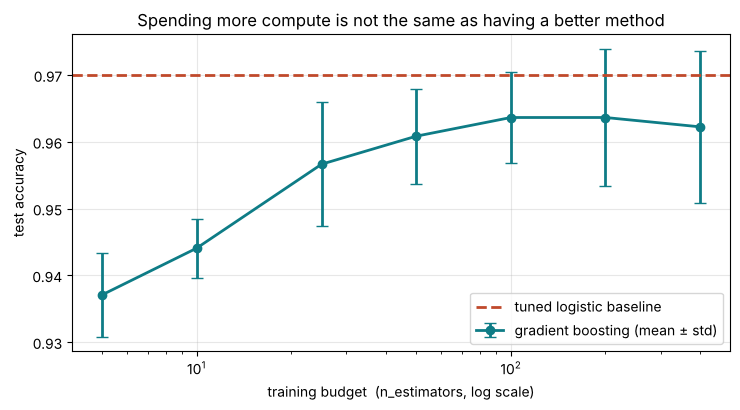

In [15]:
budgets = [5, 10, 25, 50, 100, 200, 400]
means, stds = [], []
for nb_ in budgets:
    sc = []
    for s in range(5):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
        m = make_pipeline(StandardScaler(),
                          GradientBoostingClassifier(n_estimators=nb_, max_depth=3, random_state=s)).fit(Xtr, ytr)
        sc.append(accuracy_score(yte, m.predict(Xte)))
    means.append(np.mean(sc)); stds.append(np.std(sc))
means, stds = np.array(means), np.array(stds)

baseline_mean = base_accs.mean()   # tuned baseline from Exercise 7
print("Gradient boosting accuracy vs training budget (mean \u00b1 std over 5 seeds):")
for nb_, m_, s_ in zip(budgets, means, stds):
    flag = "  <- matches/loses to tuned baseline" if m_ <= baseline_mean else ""
    print(f"  n_estimators={nb_:4d}: {m_:.4f} \u00b1 {s_:.4f}{flag}")
print(f"\nTuned baseline (Exercise 7), all compute it needs: {baseline_mean:.4f}")

plt.figure(figsize=(7.5, 4.2))
plt.errorbar(budgets, means, yerr=stds, marker="o", capsize=4, lw=2,
             color="#0E7C86", label="gradient boosting (mean \u00b1 std)")
plt.axhline(baseline_mean, ls="--", lw=2, color="#C0492B", label="tuned logistic baseline")
plt.xscale("log")
plt.xlabel("training budget  (n_estimators, log scale)"); plt.ylabel("test accuracy")
plt.title("Spending more compute is not the same as having a better method")
plt.legend(); plt.tight_layout()
plt.savefig("fig_compute_matched.png", dpi=130, bbox_inches="tight")
plt.show()


**🧪 Discuss.** Two honest readings are possible and both matter:
1. If the fancy model only overtakes the baseline at the **largest** budget, then at a *matched* budget there is **no method advantage** — the "win" was bought with compute.
2. On this dataset the well-tuned linear baseline is so strong that boosting **never clearly clears it** at any budget. That is exactly the Dacrema et al. (2019) lesson reproduced in your own runtime.

**Always report the compute budget for every method in your table.** A reviewer cannot judge fairness without it. (This is also why papers now report FLOPs, GPU-hours, or `n_estimators`/epochs alongside accuracy.)

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Discute.** Hay dos lecturas honestas y ambas importan:
1. Si el modelo sofisticado solo supera a la línea base con el presupuesto **mayor**, entonces con un presupuesto *igualado* **no hay ventaja de método**: la "victoria" se compró con cómputo.
2. En este conjunto de datos la línea base lineal bien ajustada es tan fuerte que el boosting **nunca la supera con claridad** con ningún presupuesto. Esa es exactamente la lección de Dacrema et al. (2019), reproducida en tu propio entorno.

**Reporta siempre el presupuesto de cómputo de cada método en tu tabla.** Un revisor no puede juzgar la justicia sin él. (Por eso los artículos ahora reportan FLOPs, horas-GPU o `n_estimators`/épocas junto con la precisión.)

</details>

## Exercise 9 · The data-leakage trap
This is the most dangerous reproducibility sin because it produces results that look *better*, not worse — so nobody questions them. **Leakage** is any time information from the test set sneaks into training, including innocent-looking preprocessing.

The classic demonstration (Cawley & Talbot, 2010): take features that are **pure noise** with no relationship to the label. Select the "best" of them **using the whole dataset** (test rows included), then cross-validate. Chance correlations in the test rows get baked into the chosen features, and the model reports accuracy **well above chance — from nothing at all.**

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 9 · La trampa de la fuga de datos
Este es el pecado de reproducibilidad más peligroso porque produce resultados que se ven *mejores*, no peores, así que nadie los cuestiona. **Fuga** es cualquier momento en que información del conjunto de prueba se cuela en el entrenamiento, incluso en un preprocesamiento de apariencia inocente.

La demostración clásica (Cawley y Talbot, 2010): toma variables que son **puro ruido**, sin relación con la etiqueta. Selecciona las "mejores" **usando todo el conjunto de datos** (filas de prueba incluidas) y luego haz validación cruzada. Las correlaciones casuales de las filas de prueba quedan incorporadas en las variables elegidas, y el modelo reporta una precisión **muy por encima del azar, a partir de nada.**

</details>

In [16]:
from sklearn.feature_selection import SelectKBest, f_classif

rng = np.random.default_rng(RANDOM_STATE)
N = len(y)
X_pure_noise = rng.normal(size=(N, 5000))           # 5000 features, ALL pure noise
chance = max(np.bincount(y)) / N                     # majority-class (no-information) accuracy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# WRONG: select the 20 'best' noise features on ALL rows, THEN cross-validate the survivors.
X_leaky = SelectKBest(f_classif, k=20).fit_transform(X_pure_noise, y)
leaky = cross_val_score(LogisticRegression(max_iter=5000), X_leaky, y, cv=cv, scoring="accuracy")

# RIGHT: selection lives inside the pipeline, so it is re-fit on the training fold ONLY.
honest_pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=5000))
honest = cross_val_score(honest_pipe, X_pure_noise, y, cv=cv, scoring="accuracy")

print(f"No-information (majority-class) accuracy : {chance:.4f}")
print(f"LEAKY  (select on full data, then CV)    : {leaky.mean():.4f} \u00b1 {leaky.std():.4f}   <- phantom 'signal'")
print(f"HONEST (select inside each CV fold)      : {honest.mean():.4f} \u00b1 {honest.std():.4f}   <- collapses to ~chance")
print(f"\nPhantom accuracy manufactured by leakage : {leaky.mean()-honest.mean():+.4f}")
print("The features are literally random numbers. The only difference is WHEN feature selection happened.")


No-information (majority-class) accuracy : 0.6274
LEAKY  (select on full data, then CV)    : 0.7276 ± 0.0194   <- phantom 'signal'
HONEST (select inside each CV fold)      : 0.5518 ± 0.0180   <- collapses to ~chance

Phantom accuracy manufactured by leakage : +0.1758
The features are literally random numbers. The only difference is WHEN feature selection happened.


**🧪 Discuss.** The leaky pipeline reports accuracy far above chance on **pure random noise**. Every transformation that *learns* from data — scaling, feature selection, imputation, resampling, target encoding — must be fit **inside** cross-validation, on the training fold only. The fix is structural: wrap everything in a `Pipeline` and pass the *raw* data to `cross_val_score`, exactly as the HONEST version does.

**🛠 YOUR TURN.** Concatenate the 30 real features with the 5000 noise features and rerun. Watch how the *real* signal partly masks the leakage, which is why leakage in production data is so hard to spot — and why a Model Card's "Preprocessing" and a Datasheet's "Preprocessing/cleaning/labeling" sections exist: to make *when and how* you transformed the data auditable.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Discute.** El pipeline con fuga reporta una precisión muy superior al azar sobre **puro ruido aleatorio**. Toda transformación que *aprende* de los datos (escalado, selección de variables, imputación, remuestreo, codificación por objetivo) debe ajustarse **dentro** de la validación cruzada, solo con el pliegue de entrenamiento. La solución es estructural: envuelve todo en un `Pipeline` y pasa los datos *crudos* a `cross_val_score`, exactamente como la versión HONESTA.

**🛠 TU TURNO.** Concatena las 30 variables reales con las 5000 de ruido y vuelve a correr. Observa cómo la señal *real* enmascara parcialmente la fuga; por eso la fuga en datos de producción es tan difícil de detectar, y por eso existen las secciones "Preprocessing" de la Model Card y "Preprocessing/cleaning/labeling" de la Datasheet: para hacer auditable *cuándo y cómo* transformaste los datos.

</details>

### ✍️ Your turn · Exercise 9 — real features + 5,000 noise features
**Question:** does real signal hide the leakage?
> **ES:** ¿La señal real esconde la fuga?


In [17]:
# Your turn, Exercise 9: concatenate the 30 real features with the 5000 noise features
X_mix = np.hstack([X, X_pure_noise])
# Same model on both sides (scaler + logistic regression); the ONLY difference is WHEN selection happens.
leaky_mix = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                            SelectKBest(f_classif, k=20).fit_transform(X_mix, y), y, cv=cv)
honest_mix = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), StandardScaler(), LogisticRegression(max_iter=5000)),
                             X_mix, y, cv=cv)
picked = SelectKBest(f_classif, k=20).fit(X_mix, y).get_support(indices=True)
print(f"Of the 20 features selected on all rows, {np.sum(picked < X.shape[1])} are real and {np.sum(picked >= X.shape[1])} are noise.")
print(f"Pure noise : leaky {leaky.mean():.4f}  honest {honest.mean():.4f}  gap {leaky.mean()-honest.mean():+.4f}")
print(f"Real+noise : leaky {leaky_mix.mean():.4f}  honest {honest_mix.mean():.4f}  gap {leaky_mix.mean()-honest_mix.mean():+.4f}")


Of the 20 features selected on all rows, 20 are real and 0 are noise.
Pure noise : leaky 0.7276  honest 0.5518  gap +0.1758
Real+noise : leaky 0.9754  honest 0.9754  gap +0.0000


## Exercise 10 · Ablation with error bars + the multiple-comparisons problem
A table of Δ values hides how *uncertain* each Δ is. Plotting the ablation with **error bars** shows at a glance which components have an effect that clears the noise. We reuse the ablation from Exercise 3.

Then a warning the slides hint at but every ablation table runs into: **when you make many comparisons, some will look "significant" by chance.** Test 20 components at α=0.05 and you expect roughly one false positive even if nothing matters.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 10 · Ablación con barras de error + el problema de las comparaciones múltiples
Una tabla de valores Δ oculta cuán *incierto* es cada Δ. Graficar la ablación con **barras de error** muestra de un vistazo qué componentes tienen un efecto que supera el ruido. Reutilizamos la ablación del Ejercicio 3.

Luego, una advertencia que las diapositivas insinúan pero con la que toda tabla de ablación tropieza: **cuando haces muchas comparaciones, algunas parecerán "significativas" por azar.** Prueba 20 componentes con α=0.05 y espera aproximadamente un falso positivo aunque nada importe.

</details>

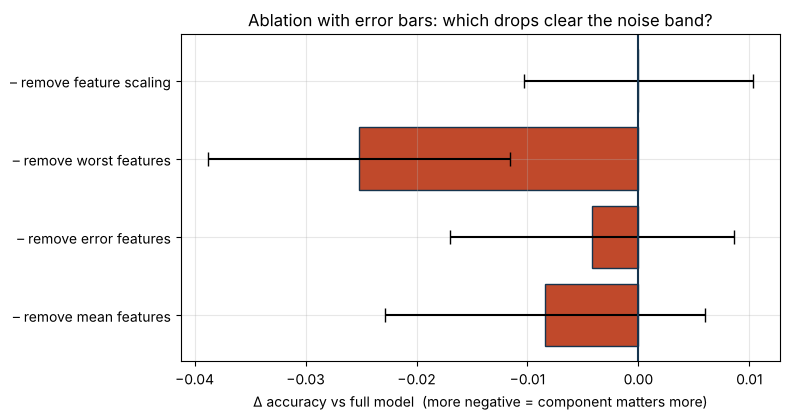

Rule of thumb: a Δ whose error bar crosses 0 is NOT distinguishable from no effect.


In [18]:
# Reuse the ablation table from Exercise 3 if present; otherwise rebuild a minimal one.
try:
    abl_df = abl.copy()
except NameError:
    def _ev(use_idx, scale=True, seeds=range(5)):
        sc = []
        for s in seeds:
            Xtr, Xte, ytr, yte = train_test_split(X[:, use_idx], y, test_size=0.25, stratify=y, random_state=s)
            steps = ([StandardScaler()] if scale else []) + [GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=s)]
            sc.append(accuracy_score(yte, make_pipeline(*steps).fit(Xtr, ytr).predict(Xte)))
        return np.mean(sc), np.std(sc)
    alli = list(range(X.shape[1])); fm, fs = _ev(alli)
    rows = [("FULL model", fm, fs, 0.0)]
    for nm, pre in [("mean features","mean"),("worst features","worst")]:
        keep=[i for i,n in enumerate(feature_names) if not n.startswith(pre)]
        m_,s_=_ev(keep); rows.append((f"- remove {nm}", m_, s_, m_-fm))
    m_,s_=_ev(alli, scale=False); rows.append(("- remove scaling", m_, s_, m_-fm))
    abl_df = pd.DataFrame(rows, columns=["Configuration","Accuracy (mean)","Std","Δ vs full"])

plot_df = abl_df[~abl_df["Configuration"].str.contains("FULL", case=False)].copy()
colors = ["#C0492B" if d < 0 else "#0E7C86" for d in plot_df["Δ vs full"]]
plt.figure(figsize=(8, 0.7*len(plot_df)+1.5))
plt.barh(plot_df["Configuration"], plot_df["Δ vs full"], xerr=plot_df["Std"],
         capsize=5, color=colors, edgecolor="#16344E")
plt.axvline(0, color="#16344E", lw=1.5)
plt.xlabel("Δ accuracy vs full model  (more negative = component matters more)")
plt.title("Ablation with error bars: which drops clear the noise band?")
plt.tight_layout(); plt.savefig("fig_ablation_errorbars.png", dpi=130, bbox_inches="tight")
plt.show()

print("Rule of thumb: a Δ whose error bar crosses 0 is NOT distinguishable from no effect.")


In [19]:
# The multiple-comparisons problem, quantified.
print("If each comparison uses alpha=0.05 independently:\n")
print(f"{'comparisons':>12} | {'P(>=1 false positive)':>22} | {'Bonferroni alpha':>16}")
print("-"*56)
for k in [1, 3, 5, 10, 20]:
    fwer = 1 - (1 - 0.05)**k
    print(f"{k:>12} | {fwer:>21.1%} | {0.05/k:>16.4f}")
print("\nWith 20 ablation rows you EXPECT about one 'significant' result from noise alone.")
print("Fix: apply Bonferroni (alpha/k) or Holm correction, or pre-register which comparisons are primary.")


If each comparison uses alpha=0.05 independently:

 comparisons |  P(>=1 false positive) | Bonferroni alpha
--------------------------------------------------------
           1 |                  5.0% |           0.0500
           3 |                 14.3% |           0.0167
           5 |                 22.6% |           0.0100
          10 |                 40.1% |           0.0050
          20 |                 64.2% |           0.0025

With 20 ablation rows you EXPECT about one 'significant' result from noise alone.
Fix: apply Bonferroni (alpha/k) or Holm correction, or pre-register which comparisons are primary.


**🧪 Discuss.** Error bars turn the ablation from a ranking into an honest statement of evidence: only components whose Δ clears the noise band are doing demonstrable work. And the multiple-comparisons table is why **preregistration** (slide: *"tie your hands before you look"*) matters — declaring your *primary* comparison in advance stops the table from becoming a fishing expedition.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Discute.** Las barras de error convierten la ablación de un ranking en una declaración honesta de evidencia: solo los componentes cuyo Δ supera la banda de ruido hacen un trabajo demostrable. Y la tabla de comparaciones múltiples es la razón por la que el **prerregistro** (diapositiva: *"átate las manos antes de mirar"*) importa: declarar de antemano tu comparación *primaria* evita que la tabla se convierta en una expedición de pesca.

</details>

## Exercise 11 · EU AI Act · Annex IV crosswalk
Slide *"Documentation is becoming law"* noted that the EU AI Act (Regulation 2024/1689) requires Annex IV technical documentation for high-risk systems, with obligations applying from **2 August 2026**, and that this overlaps heavily with Model Cards — though the Act does **not** name "Model Cards" as such.

This exercise turns that overlap into a **gap analysis**: map your Model Card sections onto Annex IV elements and flag where you have nothing (or only `"UNKNOWN"`) to show a regulator. This is exactly the artifact a compliance team produces.

> **Not legal advice.** This is an educational crosswalk for building documentation habits, not a certification of conformity.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 11 · Ley de IA de la UE · cruce con el Anexo IV
La diapositiva *"La documentación se está convirtiendo en ley"* señaló que la Ley de IA de la UE (Reglamento 2024/1689) exige documentación técnica del Anexo IV para los sistemas de alto riesgo, con obligaciones aplicables desde el **2 de agosto de 2026**, y que esto se solapa en gran medida con las Model Cards, aunque la Ley **no** menciona "Model Cards" como tales.

Este ejercicio convierte ese solapamiento en un **análisis de brechas**: mapea las secciones de tu Model Card a los elementos del Anexo IV y señala dónde no tienes nada (o solo `"UNKNOWN"`) que mostrar a un regulador. Este es exactamente el artefacto que produce un equipo de cumplimiento.

> **No es asesoría legal.** Es un cruce educativo para construir hábitos de documentación, no una certificación de conformidad.

</details>

In [20]:
# Educational mapping: Model Card section -> the Annex IV element(s) it helps satisfy.
# Annex IV elements paraphrased from Regulation (EU) 2024/1689, Annex IV.
CROSSWALK = {
    "IV(1) General description of the AI system (purpose, developer, version)":
        ["Model details", "Intended use"],
    "IV(2) Detailed description of elements & the development process (data, design choices)":
        ["Training data", "Evaluation data", "Metrics"],
    "IV(3) Monitoring, functioning and control (capabilities, limitations, accuracy)":
        ["Factors", "Quantitative analyses"],
    "IV(4) Appropriateness of performance metrics":
        ["Metrics", "Quantitative analyses"],
    "IV(5) Risk management system (foreseeable risks & mitigations)":
        ["Ethical considerations"],
    "IV(8) Post-market monitoring plan / known limitations & recommendations":
        ["Caveats and recommendations"],
}

def section_has_content(section):
    fields = model_card.get(section, {})
    text = " ".join(str(v).lower() for v in fields.values()).strip()
    return bool(text) and "unknown" not in text

rows, gaps = [], 0
for annex, sections in CROSSWALK.items():
    present = [s for s in sections if section_has_content(s)]
    missing = [s for s in sections if not section_has_content(s)]
    status = "COVERED" if not missing else "GAP"
    if missing: gaps += 1
    rows.append({"Annex IV element": annex,
                 "Maps to Model Card section(s)": ", ".join(sections),
                 "Status": status,
                 "Needs attention": ", ".join(missing) if missing else "-"})

crosswalk_df = pd.DataFrame(rows)
print(f"Annex IV gap analysis: {len(CROSSWALK)-gaps}/{len(CROSSWALK)} elements covered, {gaps} need attention.\n")
display(crosswalk_df)

# Save a Markdown crosswalk artifact.
lines = ["# EU AI Act - Annex IV Crosswalk (educational)",
         "",
         "_Mapping of Model Card sections to Annex IV technical-documentation elements.",
         "Regulation (EU) 2024/1689; high-risk obligations apply from 2 August 2026.",
         "This is a documentation exercise, not a conformity assessment._", "",
         "| Annex IV element | Model Card section(s) | Status | Needs attention |",
         "|---|---|---|---|"]
for r in rows:
    lines.append(f"| {r['Annex IV element']} | {r['Maps to Model Card section(s)']} | {r['Status']} | {r['Needs attention']} |")
with open("annex_iv_crosswalk.md", "w") as f:
    f.write("\n".join(lines))
print("\n\u2705 Saved annex_iv_crosswalk.md")


Annex IV gap analysis: 2/6 elements covered, 4 need attention.



,Annex IV element,Maps to Model Card section(s),Status,Needs attention
0,IV(1) General description of the AI system (pu...,"Model details, Intended use",GAP,Model details
1,IV(2) Detailed description of elements & the d...,"Training data, Evaluation data, Metrics",GAP,Training data
2,"IV(3) Monitoring, functioning and control (cap...","Factors, Quantitative analyses",GAP,Quantitative analyses
3,IV(4) Appropriateness of performance metrics,"Metrics, Quantitative analyses",GAP,Quantitative analyses
4,IV(5) Risk management system (foreseeable risk...,Ethical considerations,COVERED,-
5,IV(8) Post-market monitoring plan / known limi...,Caveats and recommendations,COVERED,-



✅ Saved annex_iv_crosswalk.md


**🧪 Discuss.** Every `GAP` row is a sentence you cannot yet write for a regulator — and usually a real weakness in the work, not just the paperwork. The discipline is identical to the Model Card itself: a flagged gap is more trustworthy than a confident blank.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Discute.** Cada fila `GAP` es una frase que aún no puedes escribir para un regulador, y normalmente una debilidad real del trabajo, no solo del papeleo. La disciplina es idéntica a la de la Model Card: una brecha señalada es más confiable que un espacio en blanco seguro de sí mismo.

</details>

## Exercise 12 · Bundle the reproducibility report
*"Document or it didn't happen."* The final step packages everything into one downloadable archive a stranger could open and re-run: the captured **environment**, the **Model Card**, the **Datasheet**, the **Annex IV crosswalk**, the figures, and a **scorecard reading**. This is your submission.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

## Ejercicio 12 · Empaqueta el reporte de reproducibilidad
*"Documenta, o no ocurrió."* El paso final empaqueta todo en un archivo descargable que un desconocido podría abrir y volver a correr: el **entorno** capturado, la **Model Card**, la **Datasheet**, el **cruce con el Anexo IV**, las figuras y una **lectura del scorecard**. Esta es tu entrega.

</details>

In [21]:
import sys, sklearn, scipy, zipfile, os
from datetime import datetime, timezone

# --- Capture the environment (the bare minimum a reproducer needs) ---
env_lines = [
    "# Reproducibility Report - Session 7",
    f"_Generated {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}_",
    "",
    "## Environment",
    f"- Python: {sys.version.split()[0]}",
    f"- numpy: {np.__version__} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__} | scipy: {scipy.__version__}",
    f"- Global RANDOM_STATE: {RANDOM_STATE}",
    f"- Lab dataset (Exercises 1-3, 7-10): Wisconsin Breast Cancer ({X.shape[0]} samples, {X.shape[1]} features)",
    "- Model Card and Datasheet: MY THESIS (planned XGBoost classifier; SUNAT/Veritrade HS Chapter 48 imports, 2022-2026).",
    "  The Model Card is prospective: the customs data are still being cleaned, so it reports no thesis results yet.",
    "",
    "## Lab headline results (class dataset, measured in this run)",
    f"- Fancy model, test accuracy: {accuracy_score(y_test, fancy.predict(X_test)):.4f}",
    f"- Tuned baseline, test accuracy: {accuracy_score(y_test, strong.predict(X_test)):.4f}",
    f"- Paired t-test over {N_SEEDS} seeds (fancy vs tuned baseline): p = {t_p:.4f}",
    f"- McNemar exact p (single test set): {mcnemar_p:.4f}",
    f"- Fancy bootstrap 95% CI: [{lo:.4f}, {hi:.4f}]",
    "",
    "## Artifacts in this bundle",
    "- model_card.md - 9-section Model Card of my thesis model (Mitchell et al., 2019)",
    "- datasheet.md - 7-section Datasheet of my customs dataset (Gebru et al., 2021)",
    "- annex_iv_crosswalk.md - EU AI Act Annex IV gap analysis",
    "- fig_compute_matched.png, fig_ablation_errorbars.png - figures",
    "",
    "## Documentation scorecard",
]

# Re-run the scorecard (defined in Exercise 6) and capture its score, if available.
try:
    passed, total = score_documentation(model_card, datasheet)
    env_lines.append(f"- Score: {passed}/{total}")
except Exception as e:
    env_lines.append(f"- Scorecard not available ({e}). Run Exercises 4-6 first.")

with open("REPRODUCIBILITY_REPORT.md", "w") as f:
    f.write("\n".join(env_lines))
print("\u2705 Wrote REPRODUCIBILITY_REPORT.md")

# --- Zip everything that exists into one download ---
candidates = ["REPRODUCIBILITY_REPORT.md", "model_card.md", "datasheet.md",
              "annex_iv_crosswalk.md", "fig_compute_matched.png", "fig_ablation_errorbars.png"]
bundle = "session7_deliverable.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in candidates:
        if os.path.exists(fn):
            z.write(fn)
            print(f"  added {fn}")
        else:
            print(f"  (skipped {fn} - not generated yet)")
print(f"\n\u2705 Created {bundle}. Download it from the file panel (or File > Download) and submit.")


DOCUMENTATION SCORECARD
[✓] Model Card has all 9 sections
[✓] Datasheet has all 7 sections
[✓] Intended MISUSE / out-of-scope stated
[✓] Performance reported with variation (± / std / seeds)
[✓] Metrics disaggregated (per-class / per-group)
[✓] Dataset 'should NOT be used for' stated
[✓] Collection process described
[✓] Gaps flagged honestly ('unknown')
Score: 8/8  (100%)
Submission-ready. A stranger could understand and re-run this.
✅ Wrote REPRODUCIBILITY_REPORT.md
  added REPRODUCIBILITY_REPORT.md
  added model_card.md
  added datasheet.md
  added annex_iv_crosswalk.md
  added fig_compute_matched.png
  added fig_ablation_errorbars.png

✅ Created session7_deliverable.zip. Download it from the file panel (or File > Download) and submit.


**🧪 Wrap.** Open the zip and ask the Session-7 question of your own work: *could a stranger, given only this archive, understand what you did and re-run it?* If yes, you have earned the right to your number.

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

**🧪 Cierre.** Abre el zip y hazle a tu propio trabajo la pregunta de la Sesión 7: *¿podría un desconocido, con solo este archivo, entender lo que hiciste y volver a correrlo?* Si la respuesta es sí, te has ganado el derecho a tu número.

</details>

---
## 📦 Tonight's deliverable
**Core (Part A):**
1. A completed **Model Card** (`model_card.md`) for your own model.
2. A completed **Datasheet** (`datasheet.md`) for your own dataset.
3. A scorecard reading **8/8**.

**Recommended (Part B):**
4. The **Annex IV crosswalk** (`annex_iv_crosswalk.md`) with gaps flagged.
5. The one-click **`session7_deliverable.zip`** from Exercise 12 — environment, both artifacts, the crosswalk, figures, and your scorecard, packaged for a stranger to re-run.

Download `session7_deliverable.zip` (File ▸ Download, or the file panel) and submit via the course platform by **Wednesday**. If you only finish Part A, submit the two `.md` files.

### How this connects to the rest of your PhD
- **Session 8 (Midterm):** bring your Model Card and the bundle — they are *evidence* of reproducibility for your peer review.
- **EU AI Act (Regulation 2024/1689):** for high-risk systems, Article 11 / Annex IV technical documentation overlaps heavily with these artifacts; high-risk obligations apply from **2 August 2026**.

### Sources (full list on the closing slide)
Mitchell et al. 2019 (arXiv:1810.03993) · Gebru et al. 2021 (CACM 64(12)) · Dacrema et al. 2019 (arXiv:1907.06902) · Northcutt et al. 2021 (arXiv:2103.14749) · Singh et al. 2025 (arXiv:2504.20879) · Dietterich 1998 (McNemar for classifiers) · Cawley & Talbot 2010 (leakage in model selection).

<hr>

<details open><summary><b>🇪🇸 Español</b></summary>

---
## 📦 Entregable de hoy
**Núcleo (Parte A):**
1. Una **Model Card** completa (`model_card.md`) para tu propio modelo.
2. Una **Datasheet** completa (`datasheet.md`) para tu propio conjunto de datos.
3. Una lectura del scorecard de **8/8**.

**Recomendado (Parte B):**
4. El **cruce con el Anexo IV** (`annex_iv_crosswalk.md`) con las brechas señaladas.
5. El **`session7_deliverable.zip`** de un clic del Ejercicio 12: entorno, ambos artefactos, el cruce, las figuras y tu scorecard, empaquetados para que un desconocido los repita.

Descarga `session7_deliverable.zip` (Archivo ▸ Descargar, o el panel de archivos) y entrégalo por la plataforma del curso antes del **miércoles**. Si solo terminas la Parte A, entrega los dos archivos `.md`.

### Cómo se conecta esto con el resto de tu doctorado
- **Sesión 8 (parcial):** trae tu Model Card y el paquete; son *evidencia* de reproducibilidad para tu revisión por pares.
- **Ley de IA de la UE (Reglamento 2024/1689):** para sistemas de alto riesgo, la documentación técnica del Artículo 11 / Anexo IV se solapa en gran medida con estos artefactos; las obligaciones de alto riesgo aplican desde el **2 de agosto de 2026**.

### Fuentes (lista completa en la diapositiva de cierre)
Mitchell et al. 2019 (arXiv:1810.03993) · Gebru et al. 2021 (CACM 64(12)) · Dacrema et al. 2019 (arXiv:1907.06902) · Northcutt et al. 2021 (arXiv:2103.14749) · Singh et al. 2025 (arXiv:2504.20879) · Dietterich 1998 (McNemar para clasificadores) · Cawley y Talbot 2010 (fuga en la selección de modelos).

</details>

---
## ✅ My answers · Mis respuestas — Angela Milén Acosta Ticona (COD. 26207270)

*Numbers from my run (Python 3.13, scikit-learn 1.9.1, seeds fixed); other library versions may differ slightly. / Números de mi ejecución; pueden variar levemente con otras versiones.*

| Exercise | What I observed | What it means for my thesis |
|---|---|---|
| 1 · Weak baseline | Fancy model 0.958 vs **untuned** logistic 0.916 (+4.2 pts). Against the **tuned** logistic (0.979) the "gain" became **−2.1 pts**. | H2 compares XGBoost with logistic regression and random forest: all three get the same tuning budget, or H2 is not a fair test. |
| 2 · Seeds | Same model, 10 seeds: 0.968 ± 0.009, from 0.951 to 0.979. | I report mean ± std over folds × seeds, never one run. K-Means profiles are also re-run with ≥ 10 seeds. |
| 3 · Ablation (+ your turn) | Removing "worst" features hurts most (−2.5 pts with 5 seeds, −2.0 with 10). Ranking identical with 5 and 10 seeds. Removing scaling changes nothing (Δ = 0): trees do not need scaled inputs, an honest negative result. The "error" block (−0.1 pts, std 1.3) is inside the noise. | My ablation removes one feature group at a time (HS, origin, supplier, unit value, volume) plus the Isolation Forest filter and the label definition, and says which ones do NOT help. |
| 4–5 · Model Card + Datasheet | Written for **my thesis**, prospective: planned model, fixed protocol, gaps marked UNKNOWN. | My label means "no sustainability wording found", not "proven conventional": now written down as a limitation. |
| 6 · Scorecard | **8/8.** | Honesty and completeness, not accuracy. |
| 7 · Significance (+ your turn) | Fancy vs tuned baseline: −0.002, paired t p = 0.54; McNemar p = 0.375; bootstrap 95% CI [0.923, 0.986]. Against the **untuned** baseline: +0.057, p = 0.000002. | A p-value cannot rescue an unfair comparison. Before writing "XGBoost outperforms", I need a fair baseline AND a test (corrected resampled t-test + bootstrap CI on 2026). |
| 8 · Compute | Gradient boosting peaks at 0.964 (100–200 trees) and never reaches the tuned logistic baseline (0.970) at any budget. | I report the tuning trials and number of trees for every model in my results table. |
| 9 · Leakage (+ your turn) | Pure noise: leaky 0.728 vs honest 0.552 (chance 0.627): +17.6 phantom points. With the 30 real features added, selection picked 20 real features and the gap vanished (0.975 vs 0.975). | Real signal **hides** leakage: a good score does not prove a clean pipeline. My checks are structural: folds grouped by supplier, 2026 hold-out, no description-derived features, everything fit inside a Pipeline. |
| 10 · Multiple comparisons | 20 tests at α = 0.05 → 64% chance of ≥ 1 false positive. | I pre-register ONE primary comparison (XGBoost vs logistic regression on PR-AUC) and correct the others (Holm). |
| 11 · Annex IV crosswalk | 2/6 elements covered. GAPs: Model details (data licence unknown), Training data (labeled subset size unknown), Quantitative analyses (no results yet, ×2). | Each GAP is a real to-do: confirm Veritrade's terms, finish cleaning, run the model. |
| 12 · Bundle | `session7_deliverable.zip` with report, both documents, crosswalk and figures. | Same habit as my repro-lab repository: a stranger can see what I did. |

> **ES (resumen):** Una línea base ajustada borró la "mejora" del modelo sofisticado (Ej. 1 y 7). Un solo resultado varía según la semilla (Ej. 2). La ablación fue estable con 5 y 10 semillas, y quitar el escalado no cambió nada, un resultado negativo honesto (Ej. 3). Más cómputo no superó a la línea base (Ej. 8). La fuga fabricó 17.6 puntos falsos con ruido puro, y la señal real la escondió (Ej. 9). Mi Model Card y mi Datasheet sacaron 8/8, y el cruce con el Anexo IV muestra 4 vacíos reales que son mis tareas pendientes (Ej. 6 y 11).
